# 🧀 Nido Mozzarella: ¿qué mueve la oferta y el precio de la mozzarella en Argentina?

**Data Science II: Machine Learning para la Ciencia de Datos · Coderhouse**
**Primera entrega: Obtención de insights a partir de visualizaciones**
**Autora:** María Luján Massironi

---

## 1. Abstracto

### Motivación
**Nido Mozzarella** es una pyme que elabora y vende mozzarella. En el portfolio de la pre-entrega anterior trabajamos con datos chicos de la propia app: participación de cada queso en el consumo, inventario y ratings. Para tomar decisiones de producción, compras y precios necesitamos entender el **mercado en el que opera el negocio**. La pregunta de fondo es qué pasa con la producción de quesos y con los precios de la leche y del queso a lo largo del año y de los años.

El negocio tiene tres riesgos claros:
- **Oferta:** si la producción del país sube o baja según la época, cambian la disponibilidad de leche y la competencia.
- **Costos:** la leche es la materia prima principal, así que su precio define el margen.
- **Precio de venta:** con una inflación alta, es fácil perder poder de compra sin darse cuenta.

Para eso cruzamos datos oficiales de **producción de quesos** y **precios al consumidor** (INDEC / Ministerio de Economía) con **clima** (Open-Meteo, con NASA POWER de respaldo) y **feriados** (ArgentinaDatos). Todos se obtienen de **APIs públicas**. Además se enriquecen con el dataset de consumo de quesos del portfolio.

### Audiencia
- **Dueños y gerencia de Nido Mozzarella:** planificación anual de producción y stock.
- **Compras:** cuándo conviene asegurar leche y cómo seguir su precio.
- **Comercial:** cuándo hay margen para subir precios y cuándo conviene hacer promociones.

## 2. Preguntas e hipótesis

| # | Pregunta | Hipótesis |
|---|----------|-----------|
| P1 | ¿La producción de quesos en Argentina es estacional? | **H1:** Sí. Es más alta en primavera y más baja en otoño. |
| P2 | ¿Cómo evolucionó la producción año a año? | **H2:** Es volátil y acompaña los ciclos de la economía y del tambo. |
| P3 | ¿El calor explica las subas y bajas de producción? | **H3:** Los meses más calurosos producen menos queso. |
| P4 | ¿El queso le ganó o le perdió a la inflación? | **H4:** El precio real del queso cayó en los últimos años. |
| P5 | ¿El precio del queso acompaña al de la leche? | **H5:** Se mueven juntos, y la relación queso/leche es estable. |
| P6 | ¿El precio del queso también tiene estacionalidad? | **H6:** Se encarece cuando hay menos producción (otoño-invierno). |
| P7 | ¿Los feriados le quitan producción al mes? | **H7:** Los meses con más feriados hábiles producen menos. |

## 3. Importación de datos (APIs públicas)

| Fuente | API | Qué aporta | Frecuencia |
|--------|-----|-----------|-----------|
| INDEC / Ministerio de Economía | `apis.datos.gob.ar/series` | Producción de quesos, yogur, manteca y dulce de leche (miles de t) | Mensual |
| INDEC (IPC-GBA, precios medios) | `apis.datos.gob.ar/series` | Precio del kg de queso cremoso y del litro de leche fresca en sachet | Mensual |
| INDEC (IPC Nacional) | `apis.datos.gob.ar/series` | Índice de precios para pasar los precios a pesos constantes | Mensual |
| Open-Meteo (respaldo: NASA POWER) | `archive-api.open-meteo.com` / `power.larc.nasa.gov` | Temperatura y lluvia diaria en Buenos Aires | Diaria |
| ArgentinaDatos | `api.argentinadatos.com` | Feriados nacionales (desde 2021) | Diaria |
| Portfolio Nido Mozzarella (pre-entrega anterior) | GitHub raw | Participación de cada queso en el consumo | Fija |

> **Nota:** el queso cremoso se usa como referencia de precio porque es el queso de pasta blanda que mide el INDEC, el más parecido a la mozzarella.

Si `DESCARGAR = True`, el bloque llama a las APIs y guarda los datos crudos en `data/raw/`. Una vez descargados, se puede poner en `False` para trabajar con los archivos locales.

In [1]:
import os, time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Paleta de la entrega (validada para daltonismo)
ROSA, ROSA_OSC, ROSA_CLARO, AZUL, GRIS = '#C2185B', '#880E4F', '#F8BBD0', '#1E88E5', '#6B5E64'
plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9E8A92', 'axes.labelcolor': '#3A2A30', 'xtick.color': '#5C4A52', 'ytick.color': '#5C4A52',
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.titlecolor': ROSA_OSC, 'axes.grid': True,
    'grid.color': '#F3E0E8', 'grid.linewidth': 0.8, 'font.size': 10, 'legend.frameon': False,
})
os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
os.makedirs('images', exist_ok=True)

DESCARGAR = True   # poner en False para usar los CSV ya descargados

In [2]:
def get_con_reintentos(url, params=None, intentos=6, espera=10):
    """GET con reintentos: las APIs públicas a veces limitan pedidos (error 429) o cortan la conexión."""
    for i in range(intentos):
        try:
            r = requests.get(url, params=params, timeout=60)
            r.raise_for_status()
            return r
        except requests.RequestException as e:
            print(f'  intento {i+1} falló: {type(e).__name__}; reintento en {espera*(i+1)} s')
            time.sleep(espera * (i + 1))
    raise RuntimeError(f'No se pudo descargar {url}')

# --- 3.1 Series de tiempo oficiales (datos.gob.ar) ---
SERIES = {
    '41.3_Q_0_A_6':              'prod_quesos_kt',        # Producción de quesos, miles de t
    '41.3_Y_0_A_5':              'prod_yogur_kt',
    '41.3_M_0_A_7':              'prod_manteca_kt',
    '41.3_DL_0_A_11':            'prod_dulce_leche_kt',
    '105.1_I2QC_2016_M_22':      'precio_queso_cremoso',  # $ por kg, GBA
    '105.1_I2LFES_2016_M_35':    'precio_leche_sachet',   # $ por litro, GBA
    '148.3_INIVELNAL_DICI_M_26': 'ipc_nacional',          # IPC base dic-2016 = 100
}

if DESCARGAR:
    r = get_con_reintentos('https://apis.datos.gob.ar/series/api/series/',
                           params={'ids': ','.join(SERIES), 'format': 'json', 'limit': 1000, 'start_date': '2015-01-01'})
    series = pd.DataFrame(r.json()['data'], columns=['fecha'] + list(SERIES.values()))
    series.to_csv('data/raw/series_datos_gob_ar.csv', index=False)
    print('Series oficiales:', series.shape)

Series oficiales: (140, 8)


In [3]:
# --- 3.2 Clima diario en Buenos Aires ---
# Fuente principal: Open-Meteo (año por año). Si la API limita los pedidos (error 429),
# se usa como respaldo NASA POWER, otra API pública con temperatura y lluvia diaria.
LAT, LON = -34.61, -58.38

def clima_open_meteo():
    partes = []
    for anio in range(2015, 2027):
        fin = f'{anio}-12-31' if anio < 2026 else '2026-09-30'
        r = get_con_reintentos('https://archive-api.open-meteo.com/v1/archive', intentos=3, espera=5, params={
            'latitude': LAT, 'longitude': LON, 'start_date': f'{anio}-01-01', 'end_date': fin,
            'daily': 'temperature_2m_mean,temperature_2m_max,precipitation_sum',
            'timezone': 'America/Argentina/Buenos_Aires'})
        partes.append(pd.DataFrame(r.json()['daily']))
        time.sleep(2)   # pausa entre pedidos para no superar el límite de la API
    return pd.concat(partes, ignore_index=True).assign(fuente='Open-Meteo')

def clima_nasa_power():
    r = get_con_reintentos('https://power.larc.nasa.gov/api/temporal/daily/point', params={
        'parameters': 'T2M,T2M_MAX,PRECTOTCORR', 'community': 'AG', 'latitude': LAT, 'longitude': LON,
        'start': '20150101', 'end': '20260930', 'format': 'JSON'})
    p = r.json()['properties']['parameter']
    d = pd.DataFrame({'time': pd.to_datetime(list(p['T2M'])), 'temperature_2m_mean': list(p['T2M'].values()),
                      'temperature_2m_max': list(p['T2M_MAX'].values()), 'precipitation_sum': list(p['PRECTOTCORR'].values())})
    return d.replace(-999, np.nan).assign(fuente='NASA POWER')   # -999 = dato faltante en NASA POWER

if DESCARGAR:
    try:
        clima = clima_open_meteo()
    except RuntimeError:
        print('Open-Meteo no respondió; uso NASA POWER como respaldo.')
        clima = clima_nasa_power()
    clima.to_csv('data/raw/clima_buenos_aires.csv', index=False)
    print('Clima diario:', clima.shape, '| fuente:', clima.fuente.iloc[0])

# --- 3.3 Feriados nacionales (ArgentinaDatos; la API tiene datos desde 2021) ---
if DESCARGAR:
    feriados = []
    for anio in range(2015, 2027):
        r = requests.get(f'https://api.argentinadatos.com/v1/feriados/{anio}', timeout=30)
        if r.ok:
            feriados += [dict(f, anio=anio) for f in r.json()]
    feriados = pd.DataFrame(feriados)
    feriados.to_csv('data/raw/feriados_argentina.csv', index=False)
    print('Feriados:', feriados.shape, '| años:', sorted(feriados.anio.unique()))

# --- 3.4 Dataset de la pre-entrega anterior (portfolio Nido Mozzarella) ---
URL_PORTFOLIO = 'https://raw.githubusercontent.com/Marilu1707/portfolio_interactivo/main/assets/data/cheese_consumption.csv'
if DESCARGAR:
    pd.read_csv(URL_PORTFOLIO).to_csv('data/raw/portfolio_cheese_consumption.csv', index=False)

  intento 1 falló: HTTPError; reintento en 5 s


  intento 2 falló: HTTPError; reintento en 10 s


  intento 1 falló: HTTPError; reintento en 5 s


  intento 2 falló: HTTPError; reintento en 10 s


  intento 3 falló: SSLError; reintento en 15 s


Open-Meteo no respondió; uso NASA POWER como respaldo.


Clima diario: (4291, 5) | fuente: NASA POWER


Feriados: (118, 4) | años: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


In [4]:
# Lectura de los archivos locales (funciona con DESCARGAR = False)
series   = pd.read_csv('data/raw/series_datos_gob_ar.csv', parse_dates=['fecha'])
clima    = pd.read_csv('data/raw/clima_buenos_aires.csv', parse_dates=['time'])
feriados = pd.read_csv('data/raw/feriados_argentina.csv', parse_dates=['fecha'])
consumo  = pd.read_csv('data/raw/portfolio_cheese_consumption.csv')

for nombre, d in [('series', series), ('clima', clima), ('feriados', feriados), ('consumo', consumo)]:
    print(f'{nombre:9s} {d.shape[0]:>5} filas x {d.shape[1]} columnas')
series.head()

series      140 filas x 8 columnas
clima      4291 filas x 5 columnas
feriados    118 filas x 4 columnas
consumo       6 filas x 2 columnas


,fecha,prod_quesos_kt,prod_yogur_kt,prod_manteca_kt,prod_dulce_leche_kt,precio_queso_cremoso,precio_leche_sachet,ipc_nacional
0,2015-01-01,19.693,32.818,83.875,3.400,NaN,NaN,NaN
1,2015-02-01,15.502,30.879,76.901,2.872,NaN,NaN,NaN
2,2015-03-01,16.209,32.775,90.914,2.645,NaN,NaN,NaN
3,2015-04-01,17.480,35.833,92.245,2.963,NaN,NaN,NaN
4,2015-05-01,18.816,43.882,83.303,3.241,NaN,NaN,NaN


## 4. Limpieza y transformación

Pasos:
1. **Clima:** de diario a mensual (temperatura media, máxima promedio y lluvia acumulada).
2. **Feriados:** se cuentan solo los que caen de lunes a viernes. Con eso se calculan los **días hábiles** de cada mes.
3. **Join** de todo por `fecha` (primer día del mes) en un solo dataset mensual.
4. **Nulos:** se descartan los meses sin dato de producción. Los precios empiezan en abril de 2016 y el IPC nacional en diciembre de 2016, así que el análisis de precios usa ese período.
5. **Nuevas columnas:**
   - `precio_queso_real` y `precio_leche_real`: precios en pesos del último mes con IPC (deflactados).
   - `ratio_queso_leche`: cuántos litros de leche "vale" 1 kg de queso.
   - `prod_por_dia_habil_t`: toneladas producidas por día hábil.
   - `estacion`, `anio`, `mes`.
   - `mozzarella_estimada_kt`: producción de quesos × participación de la mozzarella en el consumo, según el dataset del portfolio.

In [5]:
# 4.1 Inspección rápida de calidad
print('Tipos de datos de las series:')
print(series.dtypes.to_string())
print('\nNulos por columna (series oficiales):')
print(series.isna().sum().to_string())
print('\nDuplicados de fecha:', series.fecha.duplicated().sum(), '| Fechas de clima duplicadas:', clima.time.duplicated().sum())

Tipos de datos de las series:
fecha                   datetime64[us]
prod_quesos_kt                 float64
prod_yogur_kt                  float64
prod_manteca_kt                float64
prod_dulce_leche_kt            float64
precio_queso_cremoso           float64
precio_leche_sachet            float64
ipc_nacional                   float64

Nulos por columna (series oficiales):
fecha                    0
prod_quesos_kt           2
prod_yogur_kt            2
prod_manteca_kt          2
prod_dulce_leche_kt      2
precio_queso_cremoso    15
precio_leche_sachet     15
ipc_nacional            23

Duplicados de fecha: 0 | Fechas de clima duplicadas: 0


In [6]:
# 4.2 Clima: de diario a mensual
clima_mes = (clima.rename(columns={'time': 'fecha'}).set_index('fecha')
             .resample('MS').agg({'temperature_2m_mean': 'mean', 'temperature_2m_max': 'mean', 'precipitation_sum': 'sum'})
             .rename(columns={'temperature_2m_mean': 'temp_media', 'temperature_2m_max': 'temp_max', 'precipitation_sum': 'lluvia_mm'})
             .reset_index())

# 4.3 Feriados hábiles por mes (solo lunes a viernes)
feriados['dia_semana'] = feriados.fecha.dt.dayofweek
fer_mes = (feriados[feriados.dia_semana < 5].groupby(feriados.fecha.dt.to_period('M')).size()
           .rename('feriados_habiles').reset_index())
fer_mes['fecha'] = fer_mes.fecha.dt.to_timestamp()

# 4.4 Join de todas las fuentes
df = (series.merge(clima_mes, on='fecha', how='left')
            .merge(fer_mes, on='fecha', how='left'))
df = df.dropna(subset=['prod_quesos_kt']).reset_index(drop=True)

# 4.5 Nuevas columnas
df['anio'] = df.fecha.dt.year
df['mes'] = df.fecha.dt.month
ESTACION = {12: 'Verano', 1: 'Verano', 2: 'Verano', 3: 'Otoño', 4: 'Otoño', 5: 'Otoño',
            6: 'Invierno', 7: 'Invierno', 8: 'Invierno', 9: 'Primavera', 10: 'Primavera', 11: 'Primavera'}
df['estacion'] = pd.Categorical(df.mes.map(ESTACION), ['Verano', 'Otoño', 'Invierno', 'Primavera'], ordered=True)

# Feriados: la API cubre desde 2021; antes queda como nulo (no es cero)
df.loc[df.anio >= 2021, 'feriados_habiles'] = df.loc[df.anio >= 2021, 'feriados_habiles'].fillna(0)
df['dias_semana'] = [np.busday_count(d.date(), (d + pd.offsets.MonthBegin(1)).date()) for d in df.fecha]
df['dias_habiles'] = df.dias_semana - df.feriados_habiles
df['prod_por_dia_habil_t'] = df.prod_quesos_kt * 1000 / df.dias_habiles

# Precios en pesos constantes del último mes con IPC
mes_base = df.dropna(subset=['ipc_nacional']).fecha.max()
ipc_base = df.loc[df.fecha == mes_base, 'ipc_nacional'].iloc[0]
df['precio_queso_real'] = df.precio_queso_cremoso * ipc_base / df.ipc_nacional
df['precio_leche_real'] = df.precio_leche_sachet * ipc_base / df.ipc_nacional
df['ratio_queso_leche'] = df.precio_queso_cremoso / df.precio_leche_sachet

# Enriquecimiento con el dataset del portfolio: participación de la mozzarella en el consumo
share_mozza = consumo.set_index('cheese').consumption_share['Mozzarella'] / consumo.consumption_share.sum()
df['mozzarella_estimada_kt'] = df.prod_quesos_kt * share_mozza

print(f'Mes base de los precios reales: {mes_base:%m/%Y}')
print(f'Participación de la mozzarella (portfolio): {share_mozza:.0%}')
df.to_csv('data/processed/dataset_nido_mozzarella.csv', index=False)
df.tail()

Mes base de los precios reales: 06/2026
Participación de la mozzarella (portfolio): 35%


,fecha,prod_quesos_kt,prod_yogur_kt,prod_manteca_kt,prod_dulce_leche_kt,precio_queso_cremoso,precio_leche_sachet,ipc_nacional,temp_media,temp_max,lluvia_mm,feriados_habiles,anio,mes,estacion,dias_semana,dias_habiles,prod_por_dia_habil_t,precio_queso_real,precio_leche_real,ratio_queso_leche,mozzarella_estimada_kt
133,2026-02-01,15.092120,47.677038,30.764537,3.484935,11893.09,1692.46,10714.6255,24.823929,27.676786,55.82,2.0,2026,2,Verano,20,18.0,838.451135,13127.156154,1868.075219,7.027103,5.282242
134,2026-03-01,14.851000,52.891000,31.920000,2.720000,11953.38,1735.73,11077.0608,22.898065,25.733871,90.10,2.0,2026,3,Otoño,22,20.0,742.550000,12762.011413,1853.149994,6.886659,5.197850
135,2026-04-01,13.720000,57.026000,33.861000,2.585554,12584.45,1819.68,11363.0904,19.542000,21.831000,93.05,2.0,2026,4,Otoño,22,20.0,686.000000,13097.569751,1893.875833,6.915749,4.802000
136,2026-05-01,18.081712,58.293904,34.061804,3.486714,13132.73,1918.61,11607.3937,13.458065,15.930000,38.72,2.0,2026,5,Otoño,21,19.0,951.669075,13380.527735,1954.811705,6.844919,6.328599
137,2026-06-01,16.567000,66.471000,36.155000,3.046956,13419.82,1926.42,11826.4103,11.908667,14.044000,37.41,1.0,2026,6,Invierno,22,21.0,788.904762,13419.820000,1926.420000,6.966196,5.798450


## 5. Resumen de metadata

In [7]:
print(f'Dataset final: {df.shape[0]} filas (meses) x {df.shape[1]} columnas')
print(f'Período: {df.fecha.min():%m/%Y} a {df.fecha.max():%m/%Y}\n')
meta = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    '% completo': (1 - df.isna().mean()).mul(100).round(0).astype(int),
})
meta['categoría'] = np.where(meta.tipo.str.contains('float|int'), 'numérica',
                     np.where(meta.tipo.str.contains('datetime'), 'fecha', 'categórica'))
meta

Dataset final: 138 filas (meses) x 22 columnas
Período: 01/2015 a 06/2026



,tipo,nulos,% completo,categoría
fecha,datetime64[us],0,100,fecha
prod_quesos_kt,float64,0,100,numérica
prod_yogur_kt,float64,0,100,numérica
prod_manteca_kt,float64,0,100,numérica
prod_dulce_leche_kt,float64,0,100,numérica
precio_queso_cremoso,float64,15,89,numérica
precio_leche_sachet,float64,15,89,numérica
ipc_nacional,float64,23,83,numérica
temp_media,float64,0,100,numérica
temp_max,float64,0,100,numérica


In [8]:
cols_num = ['prod_quesos_kt', 'prod_por_dia_habil_t', 'temp_media', 'lluvia_mm',
            'precio_queso_real', 'precio_leche_real', 'ratio_queso_leche', 'mozzarella_estimada_kt']
df[cols_num].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
prod_quesos_kt,138.0,19.59,5.87,7.98,15.46,18.97,23.91,31.33
prod_por_dia_habil_t,66.0,974.02,268.47,420.56,788.14,957.48,1178.83,1509.82
temp_media,138.0,18.46,4.98,10.30,13.81,18.27,23.08,26.36
lluvia_mm,138.0,77.26,51.69,0.19,36.48,71.24,107.89,278.38
precio_queso_real,115.0,14826.28,1090.49,12762.01,13928.49,14742.72,15550.51,17666.44
precio_leche_real,115.0,2103.50,181.95,1708.39,1974.89,2098.66,2210.92,2672.76
ratio_queso_leche,123.0,7.07,0.48,5.78,6.76,7.03,7.34,8.08
mozzarella_estimada_kt,138.0,6.86,2.06,2.79,5.41,6.64,8.37,10.97


## 6. Análisis exploratorio (EDA)

### P1. ¿La producción de quesos es estacional?

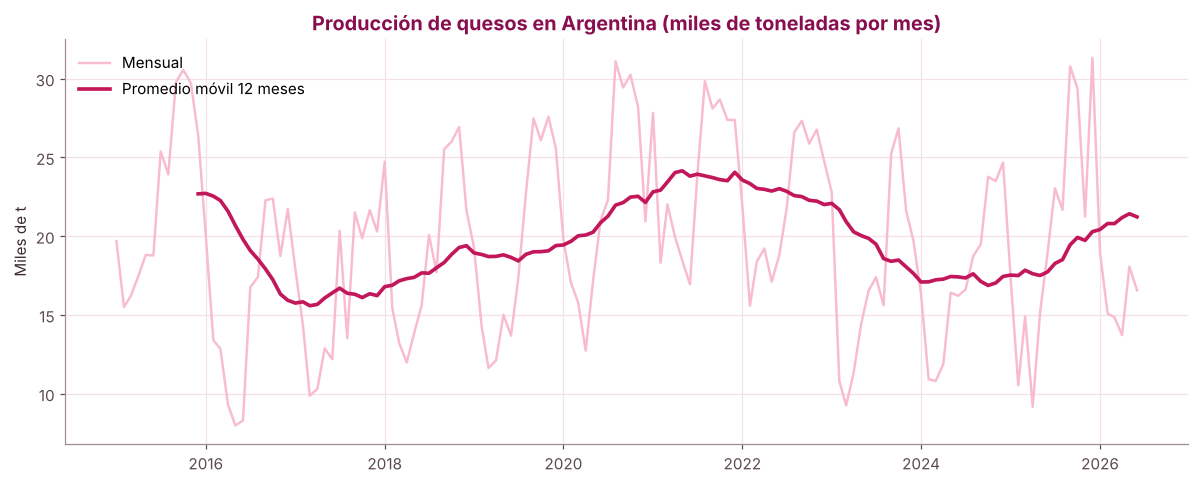

In [9]:
fig, ax = plt.subplots()
ax.plot(df.fecha, df.prod_quesos_kt, color=ROSA_CLARO, lw=1.6, label='Mensual')
ax.plot(df.fecha, df.prod_quesos_kt.rolling(12).mean(), color=ROSA, lw=2.4, label='Promedio móvil 12 meses')
ax.set_title('Producción de quesos en Argentina (miles de toneladas por mes)')
ax.set_ylabel('Miles de t'); ax.legend(loc='upper left')
plt.tight_layout(); plt.savefig('images/01_serie_produccion.png', bbox_inches='tight'); plt.show()

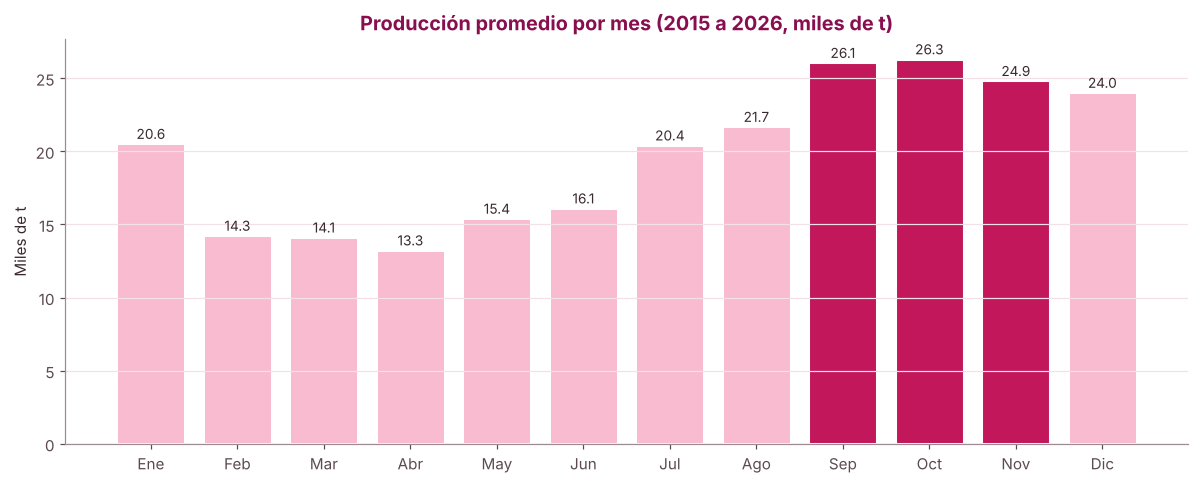

Mes pico: Oct (26.3 kt) | Mes más bajo: Abr (13.3 kt)
El mes pico produce 2.0 veces lo del mes más bajo


In [10]:
prom_mes = df.groupby('mes').prod_quesos_kt.mean()
top = prom_mes.nlargest(3).index
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

fig, ax = plt.subplots()
bars = ax.bar(MESES, prom_mes.values, color=[ROSA if m in top else ROSA_CLARO for m in prom_mes.index],
              edgecolor='white', linewidth=2)
for b, v in zip(bars, prom_mes.values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.3, f'{v:.1f}', ha='center', fontsize=9, color='#3A2A30')
ax.set_title('Producción promedio por mes (2015 a 2026, miles de t)')
ax.set_ylabel('Miles de t'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.savefig('images/02_estacionalidad.png', bbox_inches='tight'); plt.show()

print(f'Mes pico: {MESES[prom_mes.idxmax()-1]} ({prom_mes.max():.1f} kt) | Mes más bajo: {MESES[prom_mes.idxmin()-1]} ({prom_mes.min():.1f} kt)')
print(f'El mes pico produce {prom_mes.max()/prom_mes.min():.1f} veces lo del mes más bajo')

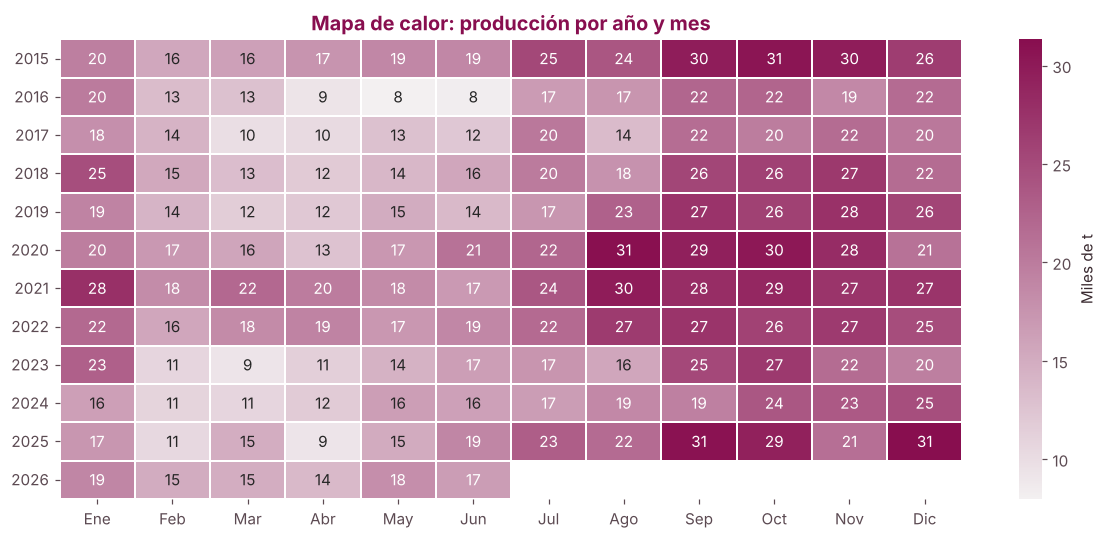

In [11]:
pivot = df.pivot_table(index='anio', columns='mes', values='prod_quesos_kt')
pivot.columns = MESES[:len(pivot.columns)]
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(pivot, cmap=sns.light_palette(ROSA_OSC, as_cmap=True), annot=True, fmt='.0f', linewidths=1,
            linecolor='white', cbar_kws={'label': 'Miles de t'}, ax=ax)
ax.set_title('Mapa de calor: producción por año y mes'); ax.set_xlabel(''); ax.set_ylabel(''); ax.grid(False)
plt.tight_layout(); plt.savefig('images/03_heatmap.png', bbox_inches='tight'); plt.show()

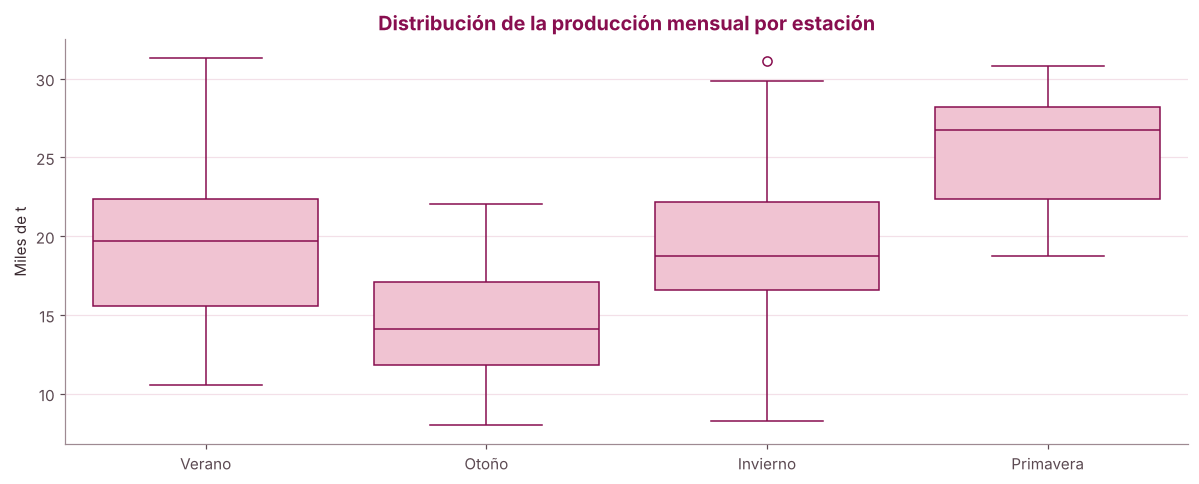

Participación de cada estación en la producción total:
estacion
Verano       25.2%
Otoño        19.0%
Invierno     24.3%
Primavera    31.4%

Kruskal-Wallis entre estaciones: H = 66.4, p-valor = 2.5e-14


In [12]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x='estacion', y='prod_quesos_kt', color=ROSA_CLARO, linecolor=ROSA_OSC, ax=ax)
ax.set_title('Distribución de la producción mensual por estación'); ax.set_xlabel(''); ax.set_ylabel('Miles de t')
plt.tight_layout(); plt.savefig('images/04_boxplot_estacion.png', bbox_inches='tight'); plt.show()

part = df.groupby('estacion', observed=True).prod_quesos_kt.sum() / df.prod_quesos_kt.sum()
print('Participación de cada estación en la producción total:')
print(part.mul(100).round(1).astype(str).add('%').to_string())
h, p = stats.kruskal(*[g.prod_quesos_kt for _, g in df.groupby('estacion', observed=True)])
print(f'\nKruskal-Wallis entre estaciones: H = {h:.1f}, p-valor = {p:.1e}')

**Respuesta P1: se confirma H1.** La producción es claramente estacional. **Septiembre y octubre** son los meses pico (unos 26 mil t), y **abril** es el más bajo (unos 13 mil t): casi la mitad. La primavera concentra cerca del **31%** de la producción del año, y el otoño solo el **19%**. La prueba de Kruskal-Wallis confirma que las diferencias entre estaciones no son casualidad (p < 0,001).

Esto coincide con el ciclo del tambo: en primavera hay más pasto y las vacas dan más leche, así que la industria hace más queso.

### P2. ¿Cómo evolucionó la producción año a año?

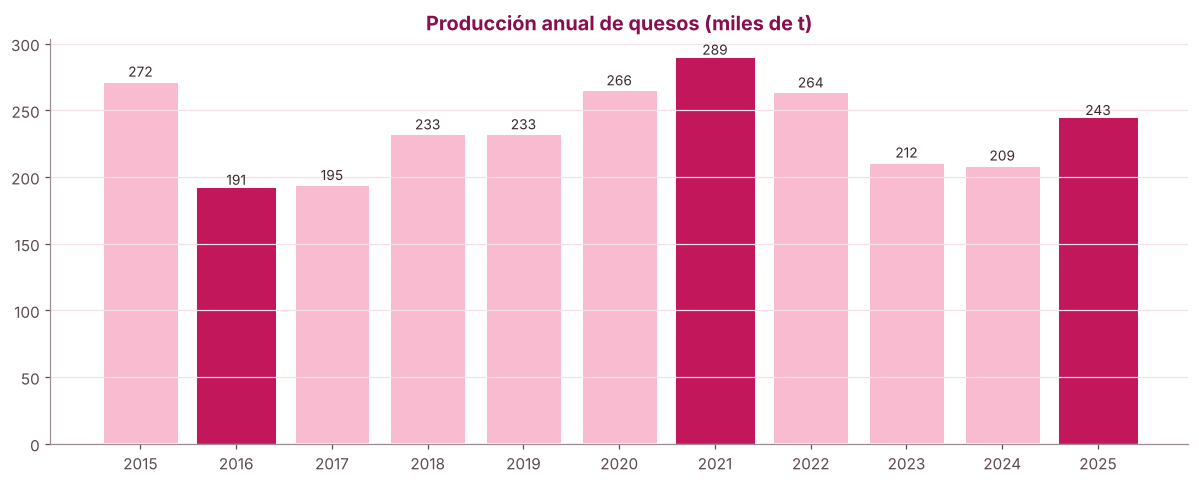

anio          2015   2016   2017   2018   2019   2020   2021   2022   2023   2024   2025
miles_t      272.3  191.2  194.7  232.7  232.8  265.8  288.7  264.1  211.6  209.4  243.5
variacion_%    NaN  -29.8    1.9   19.5    0.0   14.1    8.6   -8.5  -19.9   -1.1   16.3

Últimos 12 meses (07/2025 a 06/2026): 255 kt, +20% contra los 12 meses anteriores


In [13]:
anual = df[df.anio <= 2025].groupby('anio').prod_quesos_kt.sum()
var = anual.pct_change() * 100
fig, ax = plt.subplots()
bars = ax.bar(anual.index.astype(str), anual.values, color=ROSA_CLARO, edgecolor='white', linewidth=2)
for i, (b, v) in enumerate(zip(bars, anual.values)):
    if anual.index[i] in (anual.idxmax(), anual.idxmin(), 2025):
        b.set_color(ROSA)
    ax.text(b.get_x() + b.get_width()/2, v + 3, f'{v:.0f}', ha='center', fontsize=9, color='#3A2A30')
ax.set_title('Producción anual de quesos (miles de t)'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.savefig('images/05_produccion_anual.png', bbox_inches='tight'); plt.show()
print(pd.DataFrame({'miles_t': anual.round(1), 'variacion_%': var.round(1)}).T.to_string())

ult12 = df.prod_quesos_kt.tail(12).sum(); prev12 = df.prod_quesos_kt.iloc[-24:-12].sum()
print(f'\nÚltimos 12 meses ({df.fecha.iloc[-12]:%m/%Y} a {df.fecha.iloc[-1]:%m/%Y}): {ult12:.0f} kt, '
      f'{(ult12/prev12-1)*100:+.0f}% contra los 12 meses anteriores')

**Respuesta P2: se confirma H2.** La producción no crece de forma pareja. Cae fuerte en **2016** (-30%, el año de las inundaciones en la cuenca lechera), sube hasta su máximo en **2021** (289 mil t), vuelve a caer en **2023 y 2024** (unos 210 mil t) y se recupera en **2025** (+16%). Los últimos 12 meses ya están un 20% arriba de los 12 anteriores.

Para Nido Mozzarella esto significa que el contexto cambia mucho de un año a otro, y conviene revisar el plan de producción por lo menos una vez al año.

### P3. ¿El calor explica las subas y bajas de producción?

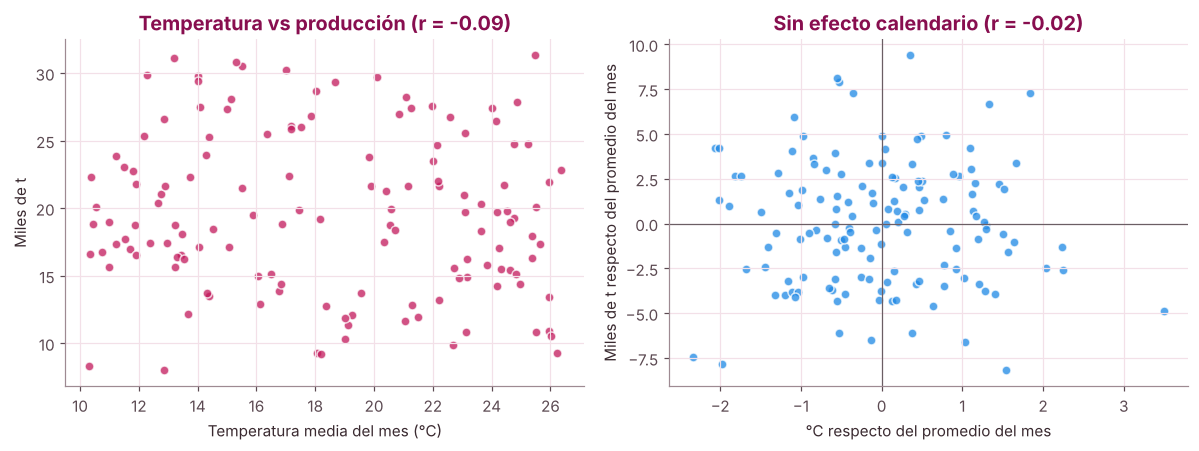

Correlación directa: r = -0.09 (p = 0.28) | Sin efecto calendario: r = -0.02 (p = 0.82)


In [14]:
x = df.dropna(subset=['temp_media']).copy()
r, p = stats.pearsonr(x.temp_media, x.prod_quesos_kt)

# Para aislar el clima del calendario: desvío de cada mes respecto de su promedio histórico
x['prod_desvio'] = x.prod_quesos_kt - x.groupby('mes').prod_quesos_kt.transform('mean')
x['temp_desvio'] = x.temp_media - x.groupby('mes').temp_media.transform('mean')
r2, p2 = stats.pearsonr(x.temp_desvio, x.prod_desvio)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(x.temp_media, x.prod_quesos_kt, s=34, color=ROSA, alpha=.75, edgecolor='white', linewidth=1)
axes[0].set_title(f'Temperatura vs producción (r = {r:.2f})'); axes[0].set_xlabel('Temperatura media del mes (°C)'); axes[0].set_ylabel('Miles de t')
axes[1].scatter(x.temp_desvio, x.prod_desvio, s=34, color=AZUL, alpha=.75, edgecolor='white', linewidth=1)
axes[1].axhline(0, color=GRIS, lw=.8); axes[1].axvline(0, color=GRIS, lw=.8)
axes[1].set_title(f'Sin efecto calendario (r = {r2:.2f})'); axes[1].set_xlabel('°C respecto del promedio del mes'); axes[1].set_ylabel('Miles de t respecto del promedio del mes')
plt.tight_layout(); plt.savefig('images/06_temperatura.png', bbox_inches='tight'); plt.show()
print(f'Correlación directa: r = {r:.2f} (p = {p:.2f}) | Sin efecto calendario: r = {r2:.2f} (p = {p2:.2f})')

**Respuesta P3: se rechaza H3.** La temperatura **no explica** la producción: la correlación es prácticamente cero (|r| < 0,1). Tampoco aparece relación cuando se compara un mes más caluroso de lo normal con su promedio (r ≈ 0). La estacionalidad viene del ciclo de la leche, no del calor del momento.

Para el negocio, el pronóstico del tiempo **no sirve** para planificar la producción. El calendario sí sirve.

### P4. ¿El queso le ganó o le perdió a la inflación?

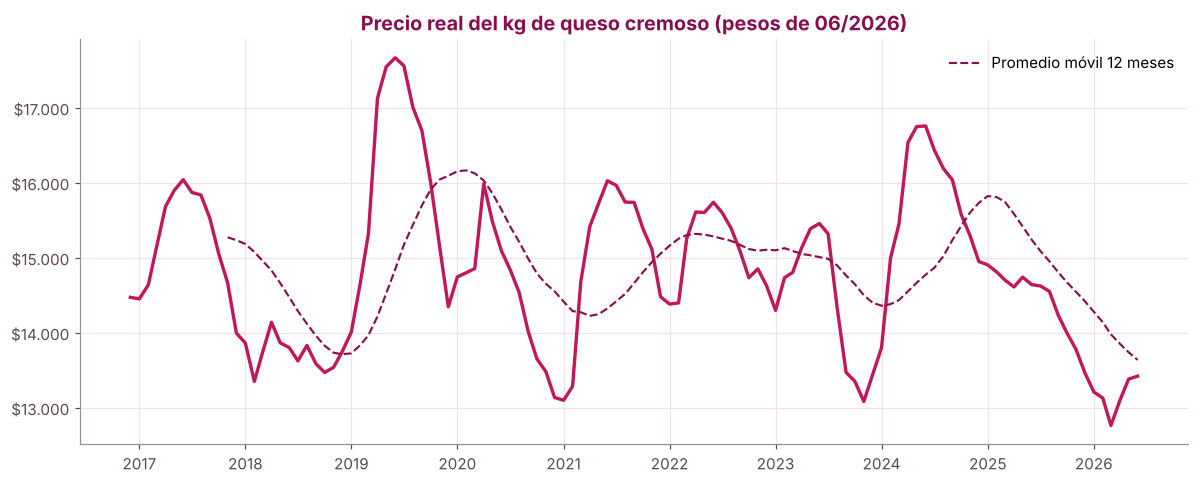

Promedio primeros 12 meses (12/2016 a 11/2017): $15,272
Promedio últimos 12 meses (07/2025 a 06/2026): $13,636
Variación real: -10.7%
Máximo: 06/2019 | Mínimo: 03/2026


In [15]:
pr = df.dropna(subset=['precio_queso_real']).copy()
fig, ax = plt.subplots()
ax.plot(pr.fecha, pr.precio_queso_real, color=ROSA, lw=2.2)
ax.plot(pr.fecha, pr.precio_queso_real.rolling(12).mean(), color=ROSA_OSC, lw=1.4, ls='--', label='Promedio móvil 12 meses')
ax.set_title(f'Precio real del kg de queso cremoso (pesos de {mes_base:%m/%Y})')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'${v:,.0f}'.replace(',', '.')))
ax.legend(loc='upper right')
plt.tight_layout(); plt.savefig('images/07_precio_real_queso.png', bbox_inches='tight'); plt.show()

ini, fin = pr.precio_queso_real.head(12).mean(), pr.precio_queso_real.tail(12).mean()
print(f'Promedio primeros 12 meses ({pr.fecha.iloc[0]:%m/%Y} a {pr.fecha.iloc[11]:%m/%Y}): ${ini:,.0f}')
print(f'Promedio últimos 12 meses ({pr.fecha.iloc[-12]:%m/%Y} a {pr.fecha.iloc[-1]:%m/%Y}): ${fin:,.0f}')
print(f'Variación real: {(fin/ini-1)*100:+.1f}%')
print(f'Máximo: {pr.loc[pr.precio_queso_real.idxmax(), "fecha"]:%m/%Y} | Mínimo: {pr.loc[pr.precio_queso_real.idxmin(), "fecha"]:%m/%Y}')

**Respuesta P4: se confirma H4.** Medido en pesos de hoy, el queso **le perdió a la inflación**. El precio real de los últimos 12 meses es un **11% más bajo** que al comienzo de la serie, y el valor mínimo es de **marzo de 2026**.

Para Nido Mozzarella esto implica que subir precios al ritmo de la inflación no alcanza para ganar margen, porque el mercado viene pagando cada vez menos en términos reales. Hay que controlar el costo.

### P5. ¿El precio del queso acompaña al de la leche?

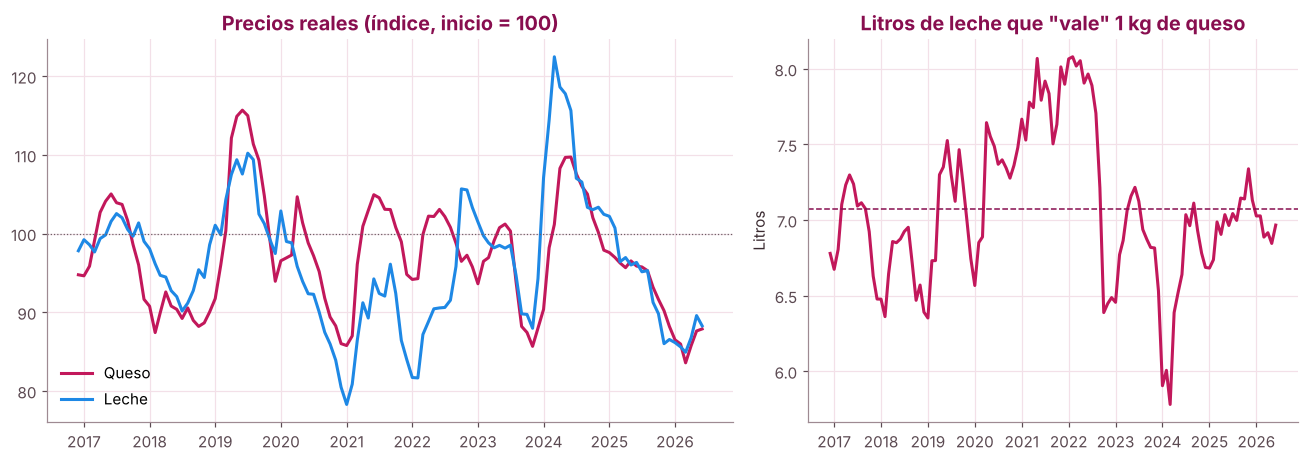

Correlación de las variaciones mensuales (queso vs leche): r = 0.81
Ratio queso/leche: promedio 7.1 litros | mínimo 5.8 | máximo 8.1


In [16]:
idx = pr.set_index('fecha')[['precio_queso_real', 'precio_leche_real']]
idx = idx / idx.iloc[:12].mean() * 100   # índice: primeros 12 meses = 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios': [1.4, 1]})
axes[0].plot(idx.index, idx.precio_queso_real, color=ROSA, lw=2, label='Queso')
axes[0].plot(idx.index, idx.precio_leche_real, color=AZUL, lw=2, label='Leche')
axes[0].axhline(100, color=GRIS, lw=.8, ls=':')
axes[0].set_title('Precios reales (índice, inicio = 100)'); axes[0].legend(loc='lower left')
axes[1].plot(pr.fecha, pr.ratio_queso_leche, color=ROSA, lw=2)
axes[1].axhline(pr.ratio_queso_leche.mean(), color=ROSA_OSC, lw=1, ls='--')
axes[1].set_title('Litros de leche que "vale" 1 kg de queso'); axes[1].set_ylabel('Litros')
plt.tight_layout(); plt.savefig('images/08_queso_vs_leche.png', bbox_inches='tight'); plt.show()

r_var, _ = stats.pearsonr(pr.precio_queso_cremoso.pct_change().dropna(), pr.precio_leche_sachet.pct_change().dropna())
print(f'Correlación de las variaciones mensuales (queso vs leche): r = {r_var:.2f}')
print(f'Ratio queso/leche: promedio {pr.ratio_queso_leche.mean():.1f} litros | mínimo {pr.ratio_queso_leche.min():.1f} | máximo {pr.ratio_queso_leche.max():.1f}')

**Respuesta P5: se confirma H5.** El queso y la leche suben casi al mismo ritmo: la correlación entre sus aumentos mensuales es muy alta (r ≈ 0,81). En promedio, **1 kg de queso cremoso vale lo mismo que unos 7 litros de leche**, y esa relación se mueve en un rango acotado (entre 5,8 y 8,1).

Esa relación sirve como **indicador de margen** para el negocio. Si baja de 7, el precio del queso se está quedando atrás del de la leche y el margen se achica.

### P6. ¿El precio del queso también tiene estacionalidad?

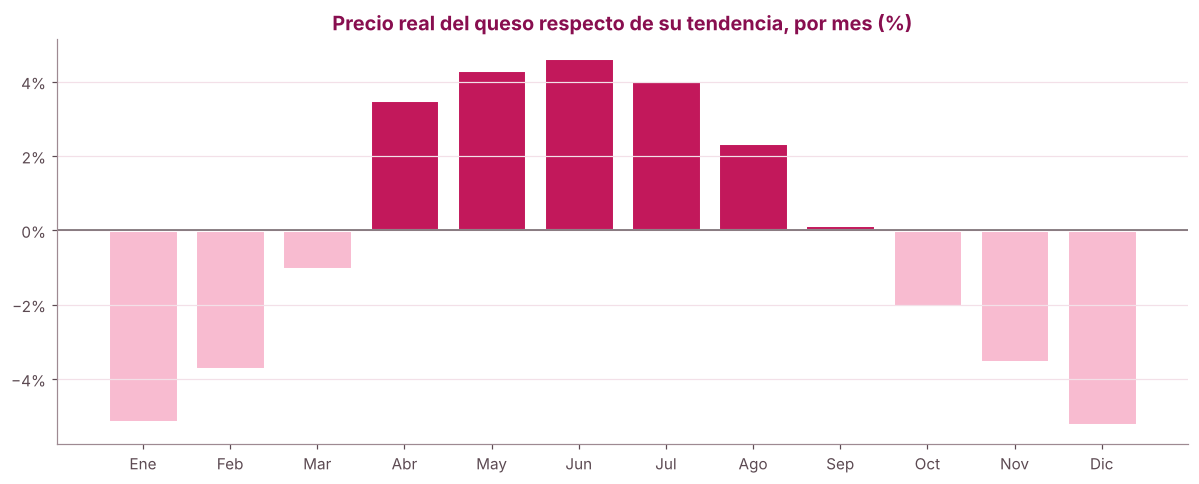

                    Ene  Feb  Mar  Abr  May  Jun  Jul  Ago  Sep  Oct  Nov  Dic
queso_vs_tendencia -5.2 -3.7 -1.0  3.5  4.3  4.6  4.0  2.3  0.1 -2.0 -3.5 -5.3
leche_vs_tendencia -0.9 -1.0  0.7  1.5  1.6  1.7  0.8  0.2 -1.1 -0.6 -2.3 -2.3

Correlación entre producción promedio del mes y precio relativo del mes: r = -0.39 (p = 0.204)


In [17]:
# Precio de cada mes relativo a su promedio móvil de 12 meses (saca la tendencia)
pr['queso_vs_tendencia'] = pr.precio_queso_real / pr.precio_queso_real.rolling(12, center=True, min_periods=6).mean() - 1
pr['leche_vs_tendencia'] = pr.precio_leche_real / pr.precio_leche_real.rolling(12, center=True, min_periods=6).mean() - 1
est_precio = pr.groupby('mes')[['queso_vs_tendencia', 'leche_vs_tendencia']].mean() * 100

fig, ax = plt.subplots()
cols = [ROSA if v > 0 else ROSA_CLARO for v in est_precio.queso_vs_tendencia]
ax.bar(MESES, est_precio.queso_vs_tendencia, color=cols, edgecolor='white', linewidth=2)
ax.axhline(0, color=GRIS, lw=1)
ax.set_title('Precio real del queso respecto de su tendencia, por mes (%)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.savefig('images/09_estacionalidad_precio.png', bbox_inches='tight'); plt.show()
print(est_precio.round(1).T.set_axis(MESES, axis=1).to_string())

r_inv, p_inv = stats.pearsonr(prom_mes.values, est_precio.queso_vs_tendencia.values)
print(f'\nCorrelación entre producción promedio del mes y precio relativo del mes: r = {r_inv:.2f} (p = {p_inv:.3f})')

**Respuesta P6: se confirma H6.** El queso se paga **entre 4% y 5% por encima de su tendencia de abril a julio**, cuando hay menos producción. Se paga **alrededor de 5% por debajo en diciembre y enero**. La leche al consumidor casi no cambia en el año (±2%). Es un patrón que se repite en todos los años, aunque con solo 12 meses de promedio la correlación con la producción no llega a ser estadísticamente significativa; conviene seguir midiéndolo.

Para Nido Mozzarella, **otoño e invierno son la mejor época para el precio de venta**, y en verano conviene apostar a volumen o a promociones.

### P7. ¿Los feriados le quitan producción al mes?

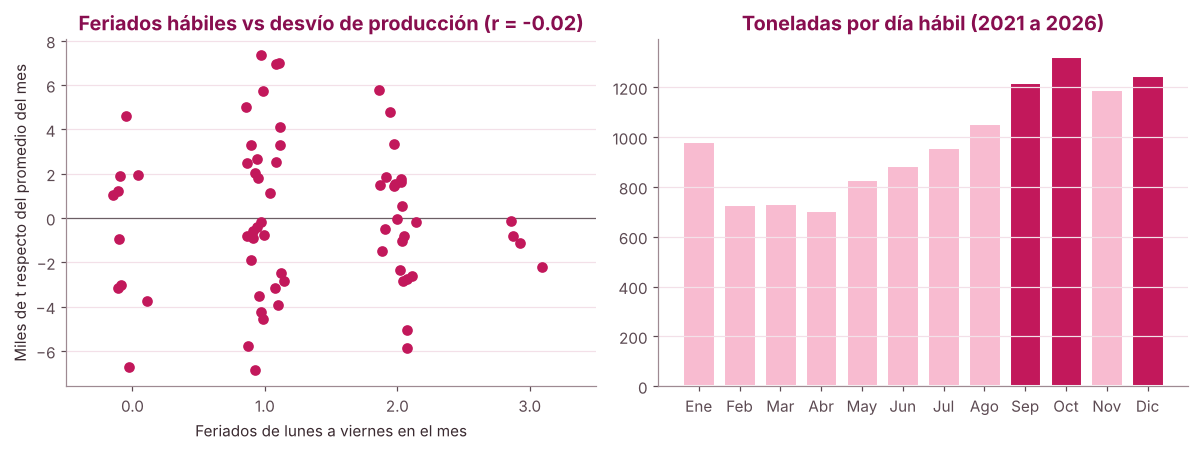

Correlación directa: r = -0.25 (p = 0.045) | Sin efecto calendario: r = -0.02 (p = 0.89)


In [18]:
h = df[df.anio >= 2021].copy()
h['prod_desvio'] = h.prod_quesos_kt - h.groupby('mes').prod_quesos_kt.transform('mean')
r_dir, p_dir = stats.pearsonr(h.feriados_habiles, h.prod_quesos_kt)
r_des, p_des = stats.pearsonr(h.feriados_habiles, h.prod_desvio)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.stripplot(data=h, x='feriados_habiles', y='prod_desvio', color=ROSA, size=7, jitter=.15, ax=axes[0])
axes[0].axhline(0, color=GRIS, lw=.8)
axes[0].set_title(f'Feriados hábiles vs desvío de producción (r = {r_des:.2f})')
axes[0].set_xlabel('Feriados de lunes a viernes en el mes'); axes[0].set_ylabel('Miles de t respecto del promedio del mes')
pdh = h.groupby('mes').prod_por_dia_habil_t.mean()
axes[1].bar(MESES, pdh.values, color=[ROSA if m in pdh.nlargest(3).index else ROSA_CLARO for m in pdh.index], edgecolor='white', linewidth=2)
axes[1].set_title('Toneladas por día hábil (2021 a 2026)'); axes[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.savefig('images/10_feriados.png', bbox_inches='tight'); plt.show()
print(f'Correlación directa: r = {r_dir:.2f} (p = {p_dir:.3f}) | Sin efecto calendario: r = {r_des:.2f} (p = {p_des:.2f})')

**Respuesta P7: se rechaza H7.** A primera vista parece que los meses con más feriados producen menos (r ≈ -0,25). Pero eso pasa porque muchos feriados caen en otoño, que ya es la estación baja. Comparado con el promedio de cada mes, el efecto **desaparece** (r ≈ 0). Medida por día hábil, la producción sigue el mismo patrón estacional, con pico en octubre.

Para el negocio, no hace falta ajustar el plan por los feriados. Lo que manda es la estación.

### Vista general: correlaciones entre variables

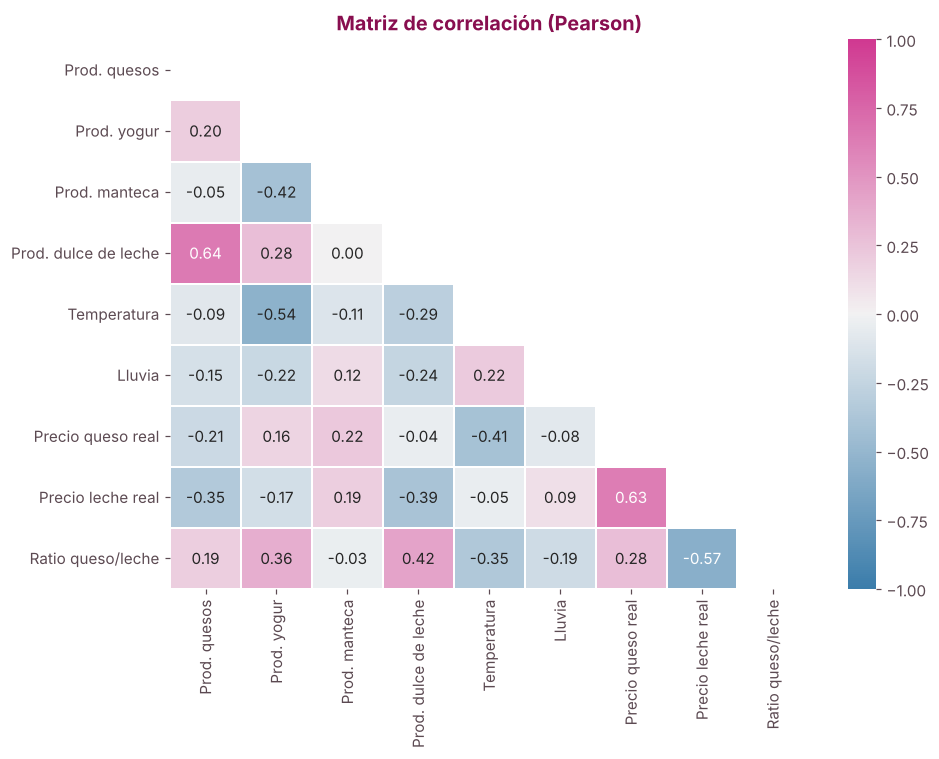

In [19]:
corr_cols = {'prod_quesos_kt': 'Prod. quesos', 'prod_yogur_kt': 'Prod. yogur', 'prod_manteca_kt': 'Prod. manteca',
             'prod_dulce_leche_kt': 'Prod. dulce de leche', 'temp_media': 'Temperatura', 'lluvia_mm': 'Lluvia',
             'precio_queso_real': 'Precio queso real', 'precio_leche_real': 'Precio leche real', 'ratio_queso_leche': 'Ratio queso/leche'}
c = df[list(corr_cols)].rename(columns=corr_cols).corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(c, mask=np.triu(np.ones_like(c, dtype=bool)), cmap=sns.diverging_palette(240, 340, s=80, l=50, as_cmap=True),
            vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', linewidths=1, linecolor='white', ax=ax)
ax.set_title('Matriz de correlación (Pearson)'); ax.grid(False)
plt.tight_layout(); plt.savefig('images/11_correlaciones.png', bbox_inches='tight'); plt.show()

La producción de quesos se mueve junto con la de **dulce de leche** (r ≈ 0,64), que también usa leche fluida. En cambio, no se relaciona con el clima. El **precio real de la leche** se relaciona de forma negativa con la producción de queso (r ≈ -0,35): cuando la leche se encarece, se elabora menos queso.

### Estimación del mercado de mozzarella (enriquecimiento con el portfolio)

El dataset de consumo del portfolio asigna a la mozzarella un **35%** del consumo de quesos. Si aplicamos esa participación a la producción nacional, obtenemos una estimación del volumen de mozzarella. **Es una aproximación**: el dato del portfolio es ilustrativo y no surge de una encuesta.

In [20]:
moz = df[df.anio <= 2025].groupby('anio').mozzarella_estimada_kt.sum()
print('Mozzarella estimada por año (miles de t):')
print(moz.round(1).to_string())
print(f'\nMes promedio de primavera: {df[df.estacion=="Primavera"].mozzarella_estimada_kt.mean():.1f} kt | '
      f'mes promedio de otoño: {df[df.estacion=="Otoño"].mozzarella_estimada_kt.mean():.1f} kt')

Mozzarella estimada por año (miles de t):
anio
2015     95.3
2016     66.9
2017     68.2
2018     81.5
2019     81.5
2020     93.0
2021    101.1
2022     92.4
2023     74.1
2024     73.3
2025     85.2

Mes promedio de primavera: 9.0 kt | mes promedio de otoño: 5.0 kt


## 7. Insights

| # | Hipótesis | Resultado | Qué significa para Nido Mozzarella |
|---|-----------|-----------|-----------------------------------|
| H1 | La producción es estacional | ✅ **Confirmada.** Octubre produce casi 2 veces lo de abril; la primavera concentra el 31% del año. | Planificar la capacidad y el stock por estación: hay más leche disponible en primavera. |
| H2 | La producción es volátil año a año | ✅ **Confirmada.** Mínimo en 2016, máximo en 2021, caída en 2023-24 y recuperación en 2025 (+16%). | Revisar el plan anual; los últimos 12 meses vienen +20%, así que habrá más competencia. |
| H3 | El calor baja la producción | ❌ **Rechazada.** Correlación cercana a 0. | No usar el clima para pronosticar; usar el calendario. |
| H4 | El queso le perdió a la inflación | ✅ **Confirmada.** -11% real. | El precio no alcanza para ganar margen: hay que controlar costos. |
| H5 | Queso y leche se mueven juntos | ✅ **Confirmada.** r ≈ 0,81; 1 kg de queso ≈ 7 litros de leche. | Usar la relación queso/leche como indicador de margen. |
| H6 | El queso es más caro cuando hay menos producción | ✅ **Confirmada.** +4 a 5% de abril a julio, -5% en diciembre y enero. | Otoño-invierno: mejor precio. Verano: volumen y promociones. |
| H7 | Los feriados restan producción | ❌ **Rechazada.** Desaparece al controlar por el mes. | No ajustar el plan por feriados. |

### Recomendaciones
1. **Plan de producción estacional:** más volumen de septiembre a diciembre, cuando sobra leche, y menos de marzo a mayo.
2. **Indicador de margen mensual:** seguir la relación precio del queso / precio de la leche y activar una alerta si baja de 7.
3. **Estrategia de precios:** aprovechar abril a julio para recomponer el precio y usar el verano para promociones.

### Próximos pasos (próxima entrega)
Entrenar modelos de Machine Learning (por ejemplo, regresión con variables de calendario y rezagos, o Random Forest) para **pronosticar la producción y el precio del mes siguiente**. Las variables que ya mostraron poder explicativo son el mes, la estación y los valores de los meses anteriores. Las que no aportan son la temperatura y los feriados.